In [ ]:
!pip install ultralytics --upgrade

from ultralytics import YOLO

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np

import torch
import cv2, os, zipfile
from PIL import Image


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 31.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
model = YOLO("C:\Users\lenovo\Desktop\Computer_Vision\best-1 (1).pt")

In [ ]:
#"device="cuda" if torch.cuda.is_available() else 'cpu'
#results = model.val(data="/content/drive/MyDrive/matricule_v1_dataset/data.yaml", split="test",  device=device,
#    plots=True#génère les courbes PR automatiquement
#)


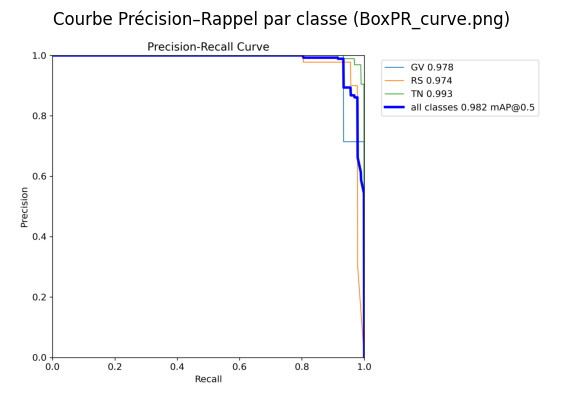

In [ ]:
#/content/runs/detect/val
#/content/runs/detect/val/BoxPR_curve.png
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
img = mpimg.imread("/content/runs/segment/val/BoxPR_curve.png")
plt.figure(figsize=(7,5))
plt.imshow(img)
plt.axis('off')
plt.title("Courbe Précision–Rappel par classe (BoxPR_curve.png)")
plt.show()

In [ ]:
%pip install opencv-python


0: 640x640 1 RS, 1302.0ms
1: 640x640 1 RS, 1302.0ms
2: 640x640 1 TN, 1302.0ms
3: 640x640 1 TN, 1302.0ms
4: 640x640 1 RS, 1302.0ms
5: 640x640 1 TN, 1302.0ms
6: 640x640 1 RS, 1302.0ms
7: 640x640 1 TN, 1302.0ms
8: 640x640 1 TN, 1302.0ms
9: 640x640 1 TN, 1302.0ms
Speed: 11.9ms preprocess, 1302.0ms inference, 3.3ms postprocess per image at shape (1, 3, 640, 640)

📌 OCR - Image 1 → 246546

📌 OCR - Image 2 → نت 135011

📌 OCR - Image 3 → 209/8107

📌 OCR - Image 4 → 3031 وس 219

📌 OCR - Image 5 → 

📌 OCR - Image 6 → 7605 تونين 224

📌 OCR - Image 7 → ن ت 148653

📌 OCR - Image 8 → 7448تين 191)

📌 OCR - Image 9 → 7984 توسن 107.

📌 OCR - Image 10 → 210 Ge 2278


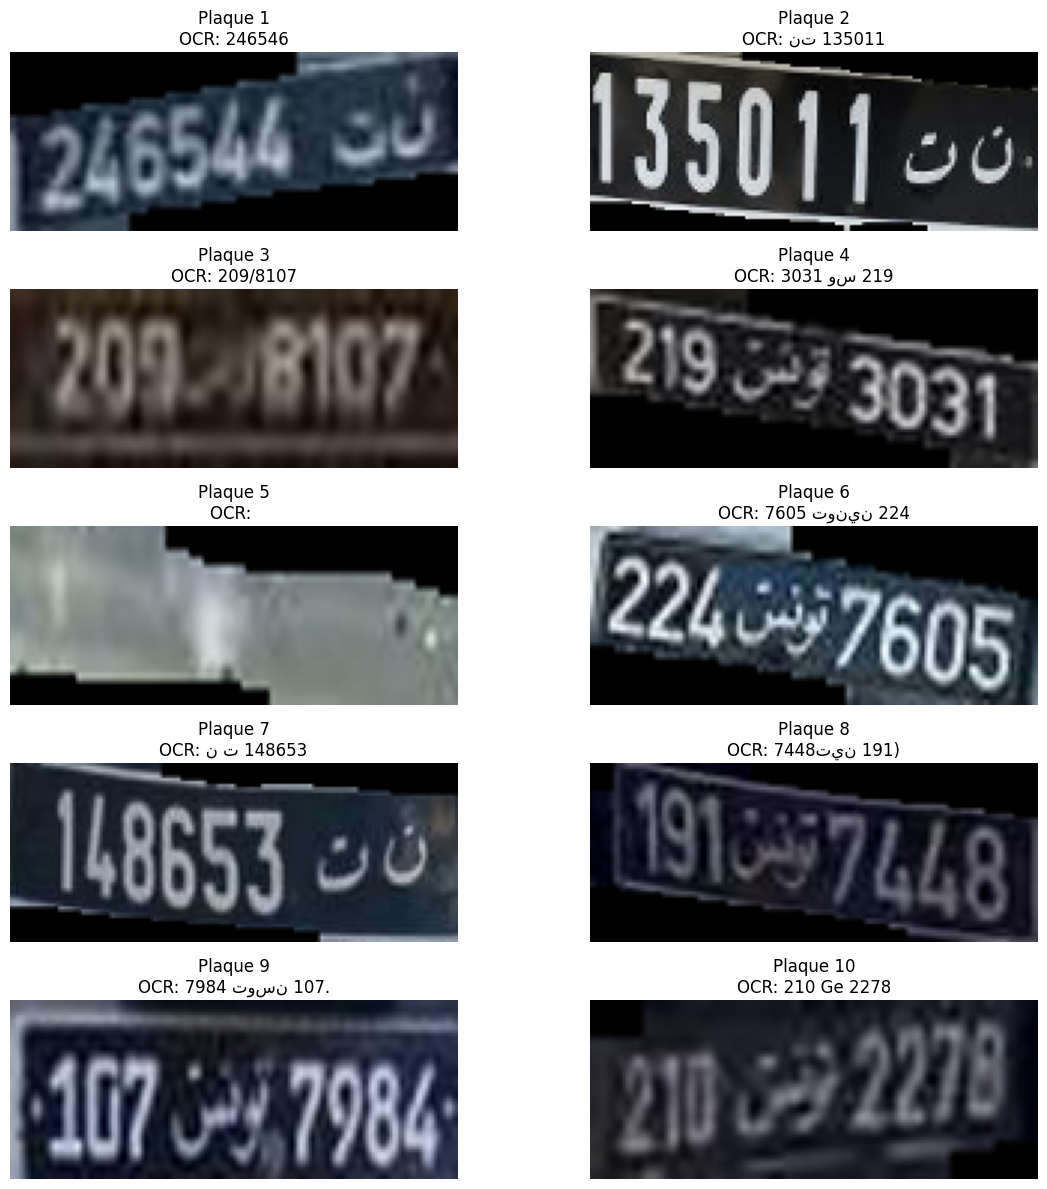

In [ ]:
import os
import cv2
import numpy as np
import json
import requests
from PIL import Image
import matplotlib.pyplot as plt

# ---------------- OCR SPACE FUNCTION ----------------
def ocr_space_file(filename, overlay=False, api_key='K84766704288957', language='auto'):
    payload = {
        'isOverlayRequired': overlay,
        'apikey': api_key,
        'language': language,
        'OCREngine': "2",
        'detectOrientation': "true",
        'scale': "true"
    }
    with open(filename, 'rb') as f:
        r = requests.post(
            'https://api.ocr.space/parse/image',
            files={filename: f},
            data=payload
        )
    return r.content.decode()

# ---------------- YOLO SEGMENTATION CONFIG ----------------
test_dir = "/content/drive/MyDrive/matricule_v3.0_datasetPRO/test/images"
TARGET_W, TARGET_H = 150, 60  # taille finale plaque

# Charger 10 images
image_files = [
    os.path.join(test_dir, img)
    for img in sorted(os.listdir(test_dir))
    if img.endswith(".jpg")
][:10]

results = model.predict(source=image_files, conf=0.5, save=False)

plt.figure(figsize=(12, 12))
index = 1

for r in results:
    # Charger l'image originale
    img = cv2.imread(r.path)

    if r.masks is None:
        print("⚠️ Aucun masque trouvé pour :", r.path)
        continue

    masks = r.masks.data.cpu().numpy()

    # ---- 1. Sélection du plus grand masque ----
    max_area = 0
    best_mask = None
    for mask in masks:
        if mask.sum() > max_area:
            max_area = mask.sum()
            best_mask = mask

    mask = (best_mask * 255).astype(np.uint8)
    mask = cv2.resize(mask, (img.shape[1], img.shape[0]))

    # ---- 2. Extraire l'image segmentée (plaque) ----
    segmented = cv2.bitwise_and(img, img, mask=mask)

    # ---- 3. Crop exact de la plaque ----
    ys, xs = np.where(mask > 0)
    x1, x2 = xs.min(), xs.max()
    y1, y2 = ys.min(), ys.max()
    plate = segmented[y1:y2, x1:x2]

    # ---- 4. Redimensionner pour uniformiser ----
    plate_resized = cv2.resize(plate, (TARGET_W, TARGET_H), interpolation=cv2.INTER_CUBIC)

    # ---- 5. Sauvegarde temporaire pour OCR ----
    temp_path = f"/content/plate_{index}.png"
    cv2.imwrite(temp_path, plate_resized)

    # ---- 6. OCR ----
    raw = ocr_space_file(filename=temp_path, language='auto')
    data = json.loads(raw)
    try:
        parsed_text = data["ParsedResults"][0]["ParsedText"].strip()
    except:
        parsed_text = "Erreur OCR"

    print(f"\n📌 OCR - Image {index} → {parsed_text}")

    # ---- 7. Affichage ----
    plt.subplot(5, 2, index)
    plt.imshow(cv2.cvtColor(plate_resized, cv2.COLOR_BGR2RGB))
    plt.title(f"Plaque {index}\nOCR: {parsed_text}")
    plt.axis('off')

    index += 1

plt.tight_layout()
plt.show()


In [ ]:
!pip install pypng

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.2 MB/s eta 0:00:00
